# Smart Tax Planner: ระบบวางแผนภาษีเงินได้บุคคลธรรมดาด้วย Machine Learning
**INI 373 Machine Learning for Investment** · ทีม "อ้วนกลมอารมณ์เสีย"

**สมาชิก:** เจษฎาภรณ์ แก้วเอี่ยม · วรวรรธน์ จันมาทอง · นรากฤต วะลัยใจ · ณัฐวรรธน์ วรรธกานนท์

## คำถามวิจัย (ตาม Proposal)
ผู้เสียภาษีที่มีอายุ รายได้ และความเสี่ยงต่างกัน ควรได้รับคำแนะนำกองทุนลดหย่อนภาษี (RMF / ThaiESG) ต่างกันอย่างไร
และการจัดกลุ่มผู้ใช้ด้วย **K-Means (Unsupervised Learning)** ช่วยให้คำแนะนำ "เหมาะกับความเสี่ยงของผู้ใช้" มากกว่าคำแนะนำแบบเดียวกันทุกคนหรือไม่

## เกณฑ์ความสำเร็จของโครงงาน
| # | เกณฑ์ | วิธีวัด |
|---|-------|---------|
| 1 | การจัดกลุ่มมีคุณภาพ | Silhouette Score บนข้อมูลทดสอบ สูงกว่า baseline (กลุ่มสุ่ม และกลุ่มตามอายุอย่างเดียว) |
| 2 | การจัดกลุ่มเสถียร | ARI เฉลี่ยระหว่างการรันคนละ seed ≥ 0.9 (วัดตามวิธีฝึกจริง n_init=20 และรายงานแบบเข้ม n_init=1 ควบคู่) |
| 3 | คำแนะนำเหมาะกับความเสี่ยงมากขึ้น | ค่าคลาดเคลื่อนของสัดส่วนหุ้น (MAE) ต่ำกว่าคำแนะนำแบบเดียวกันทุกคน |
| 4 | คำนวณภาษีถูกต้อง | ผ่าน assert test เทียบกับตัวอย่างที่คำนวณมือ |

> **หมายเหตุ:** ข้อมูลผู้ใช้เป็น **ข้อมูลจำลอง** (ไม่ใช่ข้อมูลจริงของบุคคล) และผลลัพธ์เป็นข้อมูลประกอบการตัดสินใจ ไม่ใช่คำแนะนำทางการเงินหรือภาษีอย่างเป็นทางการ

In [1]:
import json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
import joblib

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

sklearn 1.9.1 | pandas 3.0.5 | numpy 2.5.3

## 1. กติกาภาษี (ส่วนที่ไม่ใช่ ML)
ใช้อัตราภาษีเงินได้บุคคลธรรมดาแบบก้าวหน้า และสมมติฐานการลดหย่อนแบบง่ายสำหรับ **ผู้มีเงินเดือน (เงินได้ประเภท 40(1))**

| เงินได้สุทธิ (บาท) | อัตรา |
|---|---|
| 0 – 150,000 | ยกเว้น |
| 150,001 – 300,000 | 5% |
| 300,001 – 500,000 | 10% |
| 500,001 – 750,000 | 15% |
| 750,001 – 1,000,000 | 20% |
| 1,000,001 – 2,000,000 | 25% |
| 2,000,001 – 5,000,000 | 30% |
| มากกว่า 5,000,000 | 35% |

**สมมติฐานการลดหย่อนที่ใช้ในโมเดล (ทีมต้องตรวจกับประกาศกรมสรรพากรของปีภาษีที่ใช้จริงก่อนส่ง):**
- ค่าใช้จ่าย 50% ของเงินได้ แต่ไม่เกิน 100,000 บาท
- ค่าลดหย่อนส่วนตัว 60,000 บาท, ผู้อยู่ในอุปการะคนละ 30,000 บาท
- เงินประกันสังคม 9,000 บาท, เบี้ยประกันชีวิต/สุขภาพ ตามที่จ่ายจริง
- ผู้มีอายุ 65 ปีขึ้นไป ได้รับยกเว้นเงินได้ 190,000 บาทแรก
- กลุ่มออมเพื่อเกษียณ (กองทุนสำรองเลี้ยงชีพ + RMF) รวมไม่เกิน 500,000 บาท และ RMF ไม่เกิน 30% ของเงินได้
- ThaiESG ไม่เกิน 30% ของเงินได้ และไม่เกิน 300,000 บาท (แยกวงเงินจากกลุ่มเกษียณ)

In [2]:
BRACKETS = [  # (เพดานของขั้น, อัตรา)
    (150_000, 0.00), (300_000, 0.05), (500_000, 0.10), (750_000, 0.15),
    (1_000_000, 0.20), (2_000_000, 0.25), (5_000_000, 0.30), (float("inf"), 0.35),
]

def income_tax(net_income):
    """ภาษีเงินได้บุคคลธรรมดา (อัตราก้าวหน้า) จากเงินได้สุทธิ"""
    tax, lower = 0.0, 0.0
    for upper, rate in BRACKETS:
        if net_income > lower:
            tax += (min(net_income, upper) - lower) * rate
        lower = upper
    return tax

def net_income_before_funds(income, dependents, insurance, pvd, age=40):
    """เงินได้สุทธิก่อนใช้สิทธิ RMF/ThaiESG (สมมติฐานผู้มีเงินเดือน)"""
    senior_exempt = 190_000 if age >= 65 else 0          # ผู้มีอายุ 65 ปีขึ้นไป ได้รับยกเว้นเงินได้ 190,000 บาทแรก
    expense = min(0.5 * income, 100_000)
    deductions = 60_000 + 30_000 * dependents + 9_000 + insurance + pvd
    return max(income - senior_exempt - expense - deductions, 0.0)

# --- ทดสอบความถูกต้อง เทียบกับค่าที่คำนวณมือ ---
cases = {0: 0, 150_000: 0, 300_000: 7_500, 500_000: 27_500, 750_000: 65_000,
         1_000_000: 115_000, 2_000_000: 365_000, 5_000_000: 1_265_000}
for net, expected in cases.items():
    assert abs(income_tax(net) - expected) < 1e-6, (net, income_tax(net), expected)
print("ผ่านทุกกรณีทดสอบภาษี:", len(cases), "กรณี")
# ผู้สูงอายุ 65+ ได้รับยกเว้น 190,000 บาท ทำให้เงินได้สุทธิต่ำกว่าคนอายุน้อยที่รายได้เท่ากัน
assert net_income_before_funds(600_000, 0, 0, 0, age=64) - net_income_before_funds(600_000, 0, 0, 0, age=65) == 190_000
assert net_income_before_funds(150_000, 0, 0, 0, age=70) == 0
print("ผ่านการทดสอบสิทธิผู้สูงอายุ 65+")

ผ่านทุกกรณีทดสอบภาษี: 8 กรณี
ผ่านการทดสอบสิทธิผู้สูงอายุ 65+

## 2. ข้อมูล (ข้อมูลจำลอง)
**ที่มา:** ไม่มีข้อมูลบุคคลจริง สร้างข้อมูลผู้ใช้จำลอง 1,500 คน อายุ 20-75 ปี ครอบคลุมกลุ่มเป้าหมายตาม Proposal จากสมมติฐานของทีมว่าผู้เสียภาษีมีพฤติกรรมต่างกันตามช่วงชีวิต
(วัยเริ่มงาน / วัยกลางคน / วัยใกล้เกษียณ 50-59 ปี / ผู้สูงอายุ 60 ปีขึ้นไปที่ยังมีรายได้) โดย **ไม่ส่งป้ายกำกับกลุ่มให้โมเดล** โมเดลต้องค้นหากลุ่มเอง

**ตัวแปร (features):**
- `age` อายุ (ปี) · `income` เงินได้ต่อปี (บาท) · `risk_score` ความเสี่ยงที่รับได้ 1 (ต่ำ) – 5 (สูง)
- `deduction_ratio` ภาระลดหย่อน = (เบี้ยประกัน + เงินสะสมกองทุนสำรองเลี้ยงชีพ + ค่าลดหย่อนผู้อยู่ในอุปการะ) ÷ เงินได้
- `budget_ratio` สัดส่วนเงินที่ตั้งใจลงทุนในกองทุนลดหย่อนต่อรายได้ (ใช้ในระบบแนะนำ ไม่ใช้จัดกลุ่ม)
- ตัวแปรประกอบการคำนวณภาษี: `dependents`, `insurance`, `pvd`

**ข้อจำกัดสำคัญ:** เพราะเป็นข้อมูลจำลอง ผลลัพธ์พิสูจน์ได้เพียงว่า "วิธีการทำงานได้" ไม่ได้พิสูจน์ว่าผู้ใช้จริงมีพฤติกรรมแบบนี้

In [3]:
N = 1500
seg = rng.choice(4, size=N, p=[0.35, 0.30, 0.20, 0.15])   # ช่วงชีวิต (ใช้สร้างข้อมูลเท่านั้น ไม่ใช้เป็น feature)

age = np.select([seg == 0, seg == 1, seg == 2],
                [rng.integers(20, 35, N), rng.integers(35, 50, N), rng.integers(50, 60, N)],
                default=rng.integers(60, 76, N))

median_income = np.array([360_000, 780_000, 650_000, 420_000])[seg]
sigma = np.array([0.35, 0.40, 0.45, 0.50])[seg]
income = np.clip(median_income * np.exp(rng.normal(0, sigma)), 120_000, 6_000_000).round(-3)

RISK_OPTIONS = [([3, 4, 5], [.30, .40, .30]), ([2, 3, 4, 5], [.15, .40, .35, .10]),
                ([1, 2, 3, 4], [.20, .40, .30, .10]), ([1, 2, 3], [.45, .40, .15])]
risk = np.array([rng.choice(RISK_OPTIONS[s][0], p=RISK_OPTIONS[s][1]) for s in seg])

budget_ratio = np.select([seg == 0, seg == 1, seg == 2], [rng.uniform(0.02, 0.10, N), rng.uniform(0.05, 0.15, N), rng.uniform(0.05, 0.20, N)],
                         default=rng.uniform(0.02, 0.12, N))
dependents = rng.poisson(np.array([0.3, 1.2, 0.8, 0.4])[seg])
insurance = np.where(rng.random(N) < 0.6, rng.uniform(5_000, 60_000, N), 0).round(-2)
has_pvd = rng.random(N) < np.array([0.40, 0.45, 0.35, 0.05])[seg]      # ผู้สูงอายุส่วนใหญ่เกษียณแล้ว ไม่มีเงินสะสม PVD
pvd = np.where(has_pvd, np.minimum(income * rng.uniform(0.03, 0.15, N), 500_000), 0).round(-2)

df = pd.DataFrame({
    "age": age, "income": income, "risk_score": risk, "budget_ratio": budget_ratio.round(3),
    "dependents": dependents, "insurance": insurance, "pvd": pvd,
})
df["deduction_ratio"] = ((df["insurance"] + df["pvd"] + 30_000 * df["dependents"]) / df["income"]).round(4)
df["budget"] = (df["income"] * df["budget_ratio"]).round(-2)
print("ขนาดข้อมูล:", df.shape[0], "แถว ×", df.shape[1], "คอลัมน์")
print("ช่วงวัย: 20-49 =", int((df.age < 50).sum()), "| 50-59 =", int(((df.age >= 50) & (df.age < 60)).sum()), "| 60+ =", int((df.age >= 60).sum()))
print("ค่าที่หายไป (missing):", int(df.isna().sum().sum()))
print(df.describe().round(2).T[["mean", "std", "min", "50%", "max"]])

ขนาดข้อมูล: 1500 แถว × 9 คอลัมน์
ช่วงวัย: 20-49 = 974 | 50-59 = 291 | 60+ = 235
ค่าที่หายไป (missing): 0
                      mean        std        min        50%         max
age                  42.91      15.00      20.00      42.00       75.00
income           600426.00  332930.73  120000.00  516000.00  2783000.00
risk_score            3.10       1.20       1.00       3.00        5.00
budget_ratio          0.09       0.04       0.02       0.08        0.20
dependents            0.73       0.94       0.00       0.00        6.00
insurance         19284.13   19964.82       0.00   14750.00    59700.00
pvd               20421.27   36395.41       0.00       0.00   219900.00
deduction_ratio       0.11       0.10       0.00       0.10        0.94
budget            56067.20   45907.59    3000.00   41750.00   411100.00

insight: รายได้เบ้ขวา (มีคนรายได้สูงจำนวนน้อย) จึงใช้ log(income) ก่อนจัดกลุ่ม

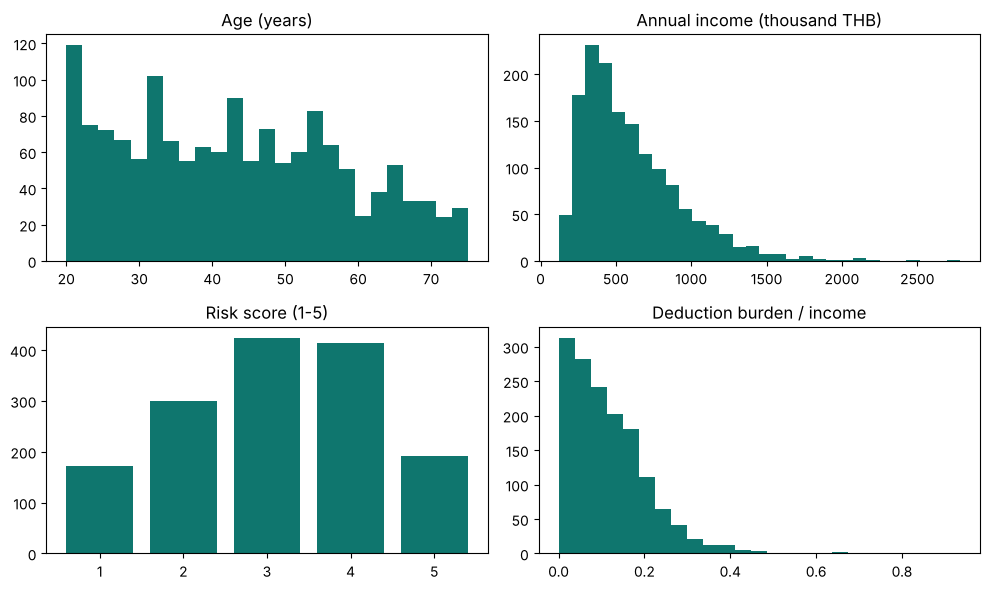

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
ax[0, 0].hist(df["age"], bins=25, color="#0f766e"); ax[0, 0].set_title("Age (years)")
ax[0, 1].hist(df["income"] / 1000, bins=30, color="#0f766e"); ax[0, 1].set_title("Annual income (thousand THB)")
ax[1, 0].bar(*np.unique(df["risk_score"], return_counts=True), color="#0f766e"); ax[1, 0].set_title("Risk score (1-5)")
ax[1, 1].hist(df["deduction_ratio"], bins=25, color="#0f766e"); ax[1, 1].set_title("Deduction burden / income")
plt.tight_layout(); plt.show()
print("insight: รายได้เบ้ขวา (มีคนรายได้สูงจำนวนน้อย) จึงใช้ log(income) ก่อนจัดกลุ่ม")

## 3. เตรียมข้อมูลและแบ่ง Train / Test
- ใช้ 4 ตัวแปรจัดกลุ่มตาม Proposal: `age` (อายุ), `log(income)` (รายได้), `risk_score` (ความเสี่ยง), `deduction_ratio` (ภาระลดหย่อน)
- ปรับสเกลด้วย `StandardScaler` เพราะ K-Means ใช้ระยะทาง ตัวแปรที่หน่วยใหญ่ (รายได้) จะครอบงำถ้าไม่ปรับ
- แบ่ง 80/20 **ก่อน** fit scaler และโมเดล เพื่อไม่ให้ข้อมูลทดสอบรั่วเข้าการเรียนรู้ (data leakage)

In [5]:
df["log_income"] = np.log(df["income"])
FEATURES = ["age", "log_income", "risk_score", "deduction_ratio"]
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print("train:", len(train_df), "| test:", len(test_df))

train: 1200 | test: 300

## 4. เลือกจำนวนกลุ่ม k (Elbow + Silhouette) ด้วยข้อมูล Train เท่านั้น
Silhouette บอกว่า k ใดแยกกลุ่มชัดที่สุดทางสถิติ แต่การเลือก k ต้องดูประโยชน์ใช้งานด้วย ทีมจึงเลือก **k = 3** ให้ตรงกับกลุ่มเป้าหมาย 3 ช่วงวัยใน Proposal
(ถ้าใช้ k ที่ Silhouette สูงสุด ผู้สูงอายุจะถูกรวมกับกลุ่มอื่น) และรายงานส่วนต่างของ Silhouette ไว้ตรง ๆ

 k  inertia  silhouette
 2 3167.458       0.316
 3 2485.027       0.284
 4 2017.766       0.289
 5 1805.113       0.257
 6 1638.573       0.245
 7 1483.627       0.241
 8 1382.814       0.239
k ที่ Silhouette สูงสุด = 2
k ที่ทีมเลือก = 3 (Silhouette ต่ำกว่า k ที่ดีที่สุด 0.032)

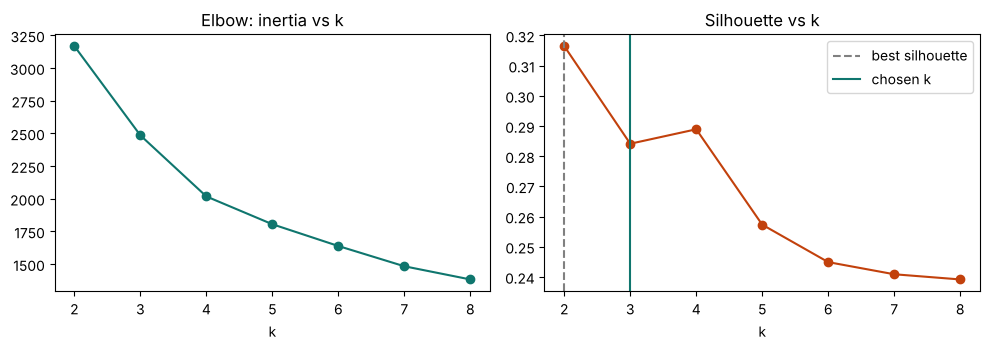

In [6]:
scaler_cv = StandardScaler().fit(train_df[FEATURES])
Xtr = scaler_cv.transform(train_df[FEATURES])
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xtr)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xtr, km.labels_)})
k_table = pd.DataFrame(rows)
print(k_table.round(3).to_string(index=False))
K_SILHOUETTE_BEST = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
print("k ที่ Silhouette สูงสุด =", K_SILHOUETTE_BEST)

# ทีมเลือก k = 3 เพราะ Proposal กำหนดกลุ่มเป้าหมาย 3 ช่วงวัย (20-49, 50-59, 60+) และต้องการแยกผู้สูงอายุออกมา
# โดยยอมรับ Silhouette ที่ต่ำลงเล็กน้อยเมื่อเทียบกับ k ที่ดีที่สุด
CHOSEN_K = 3
gap = k_table.loc[k_table["k"] == K_SILHOUETTE_BEST, "silhouette"].iloc[0] - k_table.loc[k_table["k"] == CHOSEN_K, "silhouette"].iloc[0]
print(f"k ที่ทีมเลือก = {CHOSEN_K} (Silhouette ต่ำกว่า k ที่ดีที่สุด {gap:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(k_table["k"], k_table["inertia"], marker="o", color="#0f766e"); ax[0].set_title("Elbow: inertia vs k"); ax[0].set_xlabel("k")
ax[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#c2410c"); ax[1].set_title("Silhouette vs k"); ax[1].set_xlabel("k")
ax[1].axvline(K_SILHOUETTE_BEST, ls="--", color="gray", label="best silhouette")
ax[1].axvline(CHOSEN_K, ls="-", color="#0f766e", label="chosen k")
ax[1].legend()
plt.tight_layout(); plt.show()

## 5. สร้างโมเดลสุดท้ายและดูโปรไฟล์ของแต่ละกลุ่ม

In [7]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED)),
]).fit(train_df[FEATURES])

train_df["cluster"] = model.predict(train_df[FEATURES])
test_df["cluster"] = model.predict(test_df[FEATURES])

profile = train_df.groupby("cluster").agg(
    n=("age", "size"), age=("age", "mean"), income=("income", "mean"),
    risk_score=("risk_score", "mean"), deduction_ratio=("deduction_ratio", "mean"),
)   # ไม่ปัดเศษ เพื่อให้สัดส่วนหุ้นที่คำนวณต่อจากนี้ตรงกับเว็บเป๊ะ

def describe_cluster(r):
    age_label = "วัยทำงาน (20-49)" if r["age"] < 50 else "วัยใกล้เกษียณ (50-59)" if r["age"] < 60 else "ผู้สูงอายุ (60+)"
    risk_label = "รับความเสี่ยงต่ำ" if r["risk_score"] < 2.5 else "รับความเสี่ยงปานกลาง" if r["risk_score"] < 3.5 else "รับความเสี่ยงสูง"
    income_label = "รายได้สูง" if r["income"] >= 800_000 else "รายได้ปานกลาง" if r["income"] >= 450_000 else "รายได้น้อย"
    return f"{age_label} · {income_label} · {risk_label}"

profile["description"] = profile.apply(describe_cluster, axis=1)
print(profile.round(2).to_string())

           n    age     income  risk_score  deduction_ratio                                          description
cluster                                                                                                         
0        418  44.74  913413.88        3.17             0.10  วัยทำงาน (20-49) · รายได้สูง · รับความเสี่ยงปานกลาง
1        462  28.71  380220.78        4.00             0.14     วัยทำงาน (20-49) · รายได้น้อย · รับความเสี่ยงสูง
2        320  61.66  517537.50        1.66             0.10  ผู้สูงอายุ (60+) · รายได้ปานกลาง · รับความเสี่ยงต่ำ

## 6. ประเมินโมเดลเทียบ Baseline (ข้อมูล Test)
เพราะ K-Means ไม่มี target ตรง ๆ จึงประเมิน 3 มุม:
1. **คุณภาพกลุ่ม**: Silhouette (ยิ่งสูงยิ่งดี) และ Davies-Bouldin (ยิ่งต่ำยิ่งดี) บนข้อมูล Test เทียบกับ baseline
   - **Baseline A:** กลุ่มสุ่ม (จำนวนกลุ่มเท่ากัน)
   - **Baseline B:** แบ่งกลุ่มด้วยอายุอย่างเดียว (วิธีที่ง่ายที่สุดที่คนมักใช้)
2. **ความเสถียร**: รันซ้ำคนละ seed แล้ววัด ARI ทั้งแบบที่ใช้ฝึกจริง (n_init=20) และแบบเข้ม (n_init=1)
3. **คุณค่าต่อผู้ใช้**: ดูในหัวข้อ 8

                            Silhouette (สูงดี)  Davies-Bouldin (ต่ำดี)
K-Means (ของเรา)                         0.269                   1.259
Baseline A: สุ่ม                        -0.016                  13.841
Baseline B: อายุอย่างเดียว               0.197                   1.679
ARI เฉลี่ย (10 seed, n_init=20 ตามที่ฝึกจริง): 0.996 | ต่ำสุด: 0.993
ARI เฉลี่ย (10 seed, n_init=1 แบบเข้ม): 0.719 | ต่ำสุด: 0.314
ตีความ: k=3 ไวต่อจุดเริ่มต้นสุ่มมากกว่า k=2 จึงใช้ n_init=20 เลือกผลที่ดีที่สุดจาก 20 ครั้ง ซึ่งได้กลุ่มเดิมทุก seed

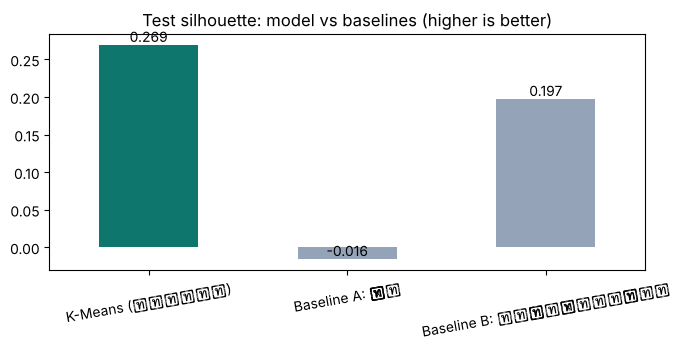

In [8]:
Xte = model.named_steps["scaler"].transform(test_df[FEATURES])
labels_model = test_df["cluster"].to_numpy()
labels_random = rng.integers(0, CHOSEN_K, len(test_df))
labels_age = pd.qcut(test_df["age"], CHOSEN_K, labels=False, duplicates="drop").to_numpy()

def score(labels):
    return silhouette_score(Xte, labels), davies_bouldin_score(Xte, labels)

results = pd.DataFrame(
    {"K-Means (ของเรา)": score(labels_model), "Baseline A: สุ่ม": score(labels_random), "Baseline B: อายุอย่างเดียว": score(labels_age)},
    index=["Silhouette (สูงดี)", "Davies-Bouldin (ต่ำดี)"],
).T.round(3)
print(results.to_string())

# ความเสถียร: รัน 10 seed ด้วย n_init=1 (เข้มกว่าปกติ) แล้ววัด ARI กับ seed แรก
def ari_over_seeds(n_init):
    ref = KMeans(CHOSEN_K, n_init=n_init, random_state=0).fit(Xtr).labels_
    return [adjusted_rand_score(ref, KMeans(CHOSEN_K, n_init=n_init, random_state=s).fit(Xtr).labels_) for s in range(1, 11)]

ari_strict = ari_over_seeds(1)     # ทดสอบแบบเข้ม: สุ่มจุดเริ่มต้นครั้งเดียว
ari = ari_over_seeds(20)           # แบบที่ใช้ฝึกโมเดลจริง (n_init=20)
print("ARI เฉลี่ย (10 seed, n_init=20 ตามที่ฝึกจริง):", round(float(np.mean(ari)), 3), "| ต่ำสุด:", round(float(np.min(ari)), 3))
print("ARI เฉลี่ย (10 seed, n_init=1 แบบเข้ม):", round(float(np.mean(ari_strict)), 3), "| ต่ำสุด:", round(float(np.min(ari_strict)), 3))
print("ตีความ: k=3 ไวต่อจุดเริ่มต้นสุ่มมากกว่า k=2 จึงใช้ n_init=20 เลือกผลที่ดีที่สุดจาก 20 ครั้ง ซึ่งได้กลุ่มเดิมทุก seed")

ax = results["Silhouette (สูงดี)"].plot(kind="bar", color=["#0f766e", "#94a3b8", "#94a3b8"], figsize=(7, 3.6), rot=10)
ax.set_title("Test silhouette: model vs baselines (higher is better)")
for p in ax.patches: ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 7. ระบบแนะนำ: จากกลุ่มของผู้ใช้ → สัดส่วนกองทุน + ภาษีที่ประหยัดได้
**หลักคิดที่ซื่อสัตย์:** จำนวนภาษีที่ประหยัดได้ขึ้นกับ "จำนวนเงินที่ใช้สิทธิ" ตามกฎหมาย (คำนวณตรง ๆ ไม่ใช่ ML)
ส่วนที่ **ML มีบทบาท** คือการกำหนด **ลักษณะกองทุนที่เหมาะกับกลุ่ม** (สัดส่วนกองทุนหุ้นเทียบกับตราสารหนี้) และเลือกช่องทาง RMF/ThaiESG

- สัดส่วนหุ้นของกลุ่ม = 10% + 80% × (ค่าเฉลี่ย risk_score ของกลุ่ม − 1) / 4 (ช่วง 10%–90%)
- ผู้ใช้อายุ ≥ 45 ปี ให้ใช้ RMF ก่อน (เน้นออมเกษียณ) นอกนั้นใช้ ThaiESG ก่อน *(เป็นสมมติฐานการออกแบบของทีม)*

In [9]:
EQUITY_BY_CLUSTER = {int(c): float(np.clip(0.10 + 0.80 * (row["risk_score"] - 1) / 4, 0.10, 0.90)) for c, row in profile.iterrows()}

def target_equity(risk):          # สัดส่วนหุ้นที่ "เหมาะ" กับระดับความเสี่ยงของบุคคลนั้นเอง
    return 0.10 + 0.80 * (risk - 1) / 4

def recommend(user, cluster=None):
    net = net_income_before_funds(user["income"], user["dependents"], user["insurance"], user["pvd"], user["age"])
    rmf_cap = min(0.30 * user["income"], max(0.0, 500_000 - user["pvd"]))
    esg_cap = min(0.30 * user["income"], 300_000)
    invest = min(user["budget"], rmf_cap + esg_cap)
    # ใส่เงินในช่องทางที่ต้องการก่อน จนเต็มวงเงิน แล้วส่วนที่เหลือไปอีกช่องทาง
    if user["age"] >= 45:
        rmf = min(invest, rmf_cap); esg = invest - rmf
    else:
        esg = min(invest, esg_cap); rmf = invest - esg
    saving = income_tax(net) - income_tax(max(net - invest, 0))
    c = int(user["cluster"]) if cluster is None else cluster
    return {"cluster": c, "equity_share": EQUITY_BY_CLUSTER[c], "invest": float(invest), "rmf": float(rmf), "thaiesg": float(esg),
            "rmf_cap": float(rmf_cap), "esg_cap": float(esg_cap),
            "tax_before": float(income_tax(net)), "tax_saved": float(saving)}

# ตัวอย่างผู้ใช้ 1 คน
ex = test_df.iloc[0]
print("ผู้ใช้ตัวอย่าง:", ex[["age", "income", "risk_score", "budget"]].to_dict())
print("คำแนะนำ:", {k: round(v, 2) if isinstance(v, float) else v for k, v in recommend(ex).items()})

ผู้ใช้ตัวอย่าง: {'age': 20.0, 'income': 210000.0, 'risk_score': 4.0, 'budget': 6300.0}
คำแนะนำ: {'cluster': 1, 'equity_share': 0.7, 'invest': 6300.0, 'rmf': 0.0, 'thaiesg': 6300.0, 'rmf_cap': 63000.0, 'esg_cap': 63000.0, 'tax_before': 0.0, 'tax_saved': 0.0}

## 8. คุณค่าต่อผู้ใช้ (ข้อมูล Test)
เทียบ 2 วิธี:
- **ของเรา:** สัดส่วนหุ้นตามกลุ่ม K-Means
- **Baseline: เหมือนกันทุกคน:** ใช้สัดส่วนหุ้นเฉลี่ยของทุกคนเท่ากันหมด

วัด **MAE ของสัดส่วนหุ้น** เทียบกับสัดส่วนที่เหมาะกับความเสี่ยงของบุคคลนั้น (ยิ่งต่ำยิ่งดี) และรายงานภาษีที่ประหยัดได้เฉลี่ย

> **ข้อควรระวัง:** `risk_score` เป็นทั้ง feature ของการจัดกลุ่มและเกณฑ์ประเมิน การที่ MAE ลดลงจึงเป็นผลที่คาดไว้อยู่แล้ว
> ผลนี้แสดงว่ากลไก "จัดกลุ่ม → แนะนำ" ทำงานสอดคล้อง แต่ **ยังไม่ใช่หลักฐานว่าผู้ใช้จริงพอใจ** ซึ่งต้องทดสอบกับผู้ใช้จริงต่อไป

MAE สัดส่วนหุ้น - ของเรา (ตามกลุ่ม): 0.128 | เหมือนกันทุกคน: 0.184 | ลดลง 30.4%
ภาษีที่ประหยัดได้เฉลี่ยต่อคน: 6,725 บาท | มัธยฐาน: 2,005 บาท
สัดส่วนผู้ใช้ที่ประหยัดภาษีได้ > 0: 66.0%
ผ่านการตรวจกรณีขอบ

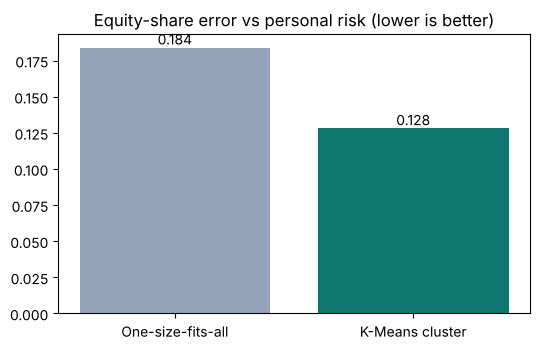

In [10]:
recs = pd.DataFrame([recommend(r) for _, r in test_df.iterrows()])
one_size = float(np.clip(target_equity(train_df["risk_score"].mean()), 0.10, 0.90))
ideal = test_df["risk_score"].map(target_equity).to_numpy()

mae_model = float(np.mean(np.abs(recs["equity_share"].to_numpy() - ideal)))
mae_one = float(np.mean(np.abs(one_size - ideal)))
print(f"MAE สัดส่วนหุ้น - ของเรา (ตามกลุ่ม): {mae_model:.3f} | เหมือนกันทุกคน: {mae_one:.3f} | ลดลง {100*(1-mae_model/mae_one):.1f}%")
print(f"ภาษีที่ประหยัดได้เฉลี่ยต่อคน: {recs['tax_saved'].mean():,.0f} บาท | มัธยฐาน: {recs['tax_saved'].median():,.0f} บาท")
print(f"สัดส่วนผู้ใช้ที่ประหยัดภาษีได้ > 0: {(recs['tax_saved'] > 0).mean():.1%}")

# ตรวจกรณีขอบ: ไม่ลงทุนเกินวงเงิน และภาษีไม่ติดลบ
assert (recs["invest"] <= test_df["budget"] + 1e-6).all()
assert (recs["tax_saved"] >= -1e-6).all()
assert (recs[["rmf", "thaiesg"]].sum(axis=1) - recs["invest"]).abs().max() < 1e-6
assert (recs["rmf"] <= recs["rmf_cap"] + 1e-6).all() and (recs["thaiesg"] <= recs["esg_cap"] + 1e-6).all()   # ไม่เกินวงเงินแต่ละช่องทาง
print("ผ่านการตรวจกรณีขอบ")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(["One-size-fits-all", "K-Means cluster"], [mae_one, mae_model], color=["#94a3b8", "#0f766e"])
for i, v in enumerate([mae_one, mae_model]): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_title("Equity-share error vs personal risk (lower is better)")
plt.tight_layout(); plt.show()

## 9. บันทึกโมเดลและไฟล์ที่ต้องส่ง (จากการรันครั้งเดียวกัน)

In [11]:
import os
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

joblib.dump(model, f"{OUT}/kmeans_model.joblib")
df.drop(columns=["log_income"]).to_csv(f"{OUT}/users_synthetic.csv", index=False)

model_info = {
    "project": "Smart Tax Planner (INI 373)",
    "model_type": "KMeans clustering (Pipeline: StandardScaler + KMeans)",
    "features": FEATURES,
    "n_clusters": CHOSEN_K,
    "k_selection": {"k_best_silhouette": K_SILHOUETTE_BEST, "k_chosen": CHOSEN_K,
                    "reason": "Proposal defines 3 age groups (20-49, 50-59, 60+); chosen k separates seniors at a small silhouette cost"},
    "random_seed": SEED,
    "data": {"source": "synthetic (simulated users)", "rows": int(len(df)), "train": int(len(train_df)), "test": int(len(test_df))},
    "metrics_test": {
        "silhouette_model": round(float(results.iloc[0, 0]), 4),
        "silhouette_random_baseline": round(float(results.iloc[1, 0]), 4),
        "silhouette_age_only_baseline": round(float(results.iloc[2, 0]), 4),
        "ari_stability_mean": round(float(np.mean(ari)), 4),
        "ari_stability_strict_n_init1_mean": round(float(np.mean(ari_strict)), 4),
        "equity_mae_model": round(mae_model, 4),
        "equity_mae_one_size": round(mae_one, 4),
        "mean_tax_saved_baht": round(float(recs["tax_saved"].mean()), 2),
    },
    "cluster_profiles": {str(c): {**{k: float(v) for k, v in row.drop("description").items()}, "description": row["description"],
                                   "recommended_equity_share": EQUITY_BY_CLUSTER[int(c)]} for c, row in profile.iterrows()},
    "tax_assumptions": "Employment income (40(1)); expense deduction 50% max 100k; personal 60k; dependents 30k each; social security 9k; "
                       "retirement group (PVD+RMF) <= 500k and RMF <= 30% income; ThaiESG <= 30% income and <= 300k. Verify with Revenue Department for the tax year used.",
    "limitations": ["synthetic data", "recommendation rule is team-designed, not learned from outcomes", "not official financial/tax advice"],
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
with open(f"{OUT}/model_info.json", "w", encoding="utf-8") as f:
    json.dump(model_info, f, ensure_ascii=False, indent=2)

with open(f"{OUT}/requirements.txt", "w") as f:
    f.write(f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\nstreamlit\nmatplotlib\n")

# ตรวจว่าโหลดโมเดลกลับมาแล้วให้ผลเหมือนเดิม
reloaded = joblib.load(f"{OUT}/kmeans_model.joblib")
assert (reloaded.predict(test_df[FEATURES]) == test_df["cluster"].to_numpy()).all()
print("บันทึกไฟล์แล้ว:", sorted(os.listdir(OUT)))

บันทึกไฟล์แล้ว: ['kmeans_model.joblib', 'model_info.json', 'requirements.txt', 'users_synthetic.csv']

## 10. ข้อจำกัด จริยธรรม และการใช้ AI
**ข้อจำกัดของข้อมูลและโมเดล**
- ข้อมูลเป็นข้อมูลจำลอง ไม่ครอบคลุมผู้มีรายได้หลายประเภท (ฟรีแลนซ์ นักลงทุน) และไม่ได้มาจากการสำรวจจริง
- กฎการแนะนำสัดส่วนหุ้นเป็นกฎที่ทีมออกแบบ ไม่ได้เรียนรู้จากผลลัพธ์จริง ผลที่ดีขึ้นจึงเป็นการตรวจความสอดคล้องของระบบ
- กติกาภาษีเป็นแบบย่อ ต้องตรวจกับกรมสรรพากรของปีภาษีที่ใช้ และไม่ใช่คำแนะนำทางภาษีอย่างเป็นทางการ
- **ไม่ควรเชื่อโมเดล** เมื่อผู้ใช้มีเงินได้ต่างจากข้อมูลฝึกมาก (เช่น รายได้ > 6 ล้านบาท) หรือมีเงื่อนไขภาษีพิเศษ

**ความเป็นธรรมและความเป็นส่วนตัว:** ระบบไม่เก็บข้อมูลส่วนบุคคลจริง กลุ่มผู้สูงอายุถูกจัดให้รับความเสี่ยงต่ำตามข้อมูลจำลอง ควรเปิดให้ผู้ใช้ปรับระดับความเสี่ยงเองเสมอ

**บันทึกการใช้ AI** (ทีมต้องกรอกให้ตรงกับความจริง และตรวจสอบทุกบรรทัดก่อนส่ง)

| เครื่องมือ | จุดประสงค์ | สิ่งที่เก็บไว้ | สิ่งที่แก้/ปฏิเสธ | การตรวจสอบ |
|---|---|---|---|---|
| (เช่น Claude) | ร่างโครงสร้าง Notebook และโค้ดคำนวณภาษี | | | assert test เทียบค่าคำนวณมือ, รันซ้ำทั้ง Notebook |